# 07 — Pesos de sexo × idade em vez de pareamento: usar todos os sujeitos

**Pergunta:** o pareamento do notebook 02 descartou mais da metade da coorte 7–21 anos (2374 → 1136). Dá para manter
todos os sujeitos usando pesos, sem reabrir o atalho de sexo e idade?

**Por que só pesos de classe não bastam.** Todos os modelos já usam `class_weight="balanced"`, que iguala o peso
*total* de cada classe. Mas dentro de cada classe a mistura de sexo e idade continua diferente (TEA: 87% meninos,
13,4 anos; TDAH: 78%, 11,6 anos; controles: 66%, 12,4 anos). O modelo pode "acertar" TEA só porque o sujeito é menino
e mais velho — diferença que vem do recrutamento de cada base, não do transtorno.

**Pesos de balanceamento de covariáveis** (`src/weighting.py`): cada sujeito recebe peso 1 / P(seu grupo | sexo, idade),
estimado por regressão logística multinomial com splines de idade e interação com sexo. Os grupos são os quatro do
pareamento (TEA-ABIDE, Controle-ABIDE, Controle-ADHD200, TDAH-ADHD200). Com os pesos, todos passam a ter a
distribuição de sexo e idade da coorte inteira. Pesos aparados no percentil 99 e com média 1 por classe
(o balanceamento entre classes continua com `class_weight`).

**Comparação** (mesmos modelos e validação por instituição do notebook 03, 10 sementes; LDA fica de fora porque não aceita pesos):

| Condição | Sujeitos | Treino | Avaliação |
|---|---|---|---|
| Pareada | 1136 | pesos de classe | sem pesos |
| Completa, só classe | 2374 | pesos de classe | sem pesos **e** com pesos de sexo × idade |
| Completa, sexo × idade | 2374 | pesos de classe × sexo × idade | com pesos |
| Completa, sexo × idade, sem a feature idade | 2374 | idem | com pesos |

A avaliação também precisa de pesos: se só o treino for ponderado, um modelo que usa sexo e idade ainda parece bom no teste.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from functools import partial
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from evaluation import (CLASSES, RANDOM_STATE, _fit_params, _imputer, confusion_table, features, make_models,
                        metrics, metrics_binary, repeated_group_cv, target)
from matching import add_group
from weighting import covariate_weights, effective_n, propensity, weighted_smd

FIG = ROOT / "results" / "figures"
sns.set_theme(style="whitegrid", context="notebook")
warnings.filterwarnings("ignore", message=".*sklearn.utils.parallel.delayed.*")
SEEDS = range(10)

completa = add_group(pd.read_csv(ROOT / "data" / "interim" / "cohort_7_21.csv"))
pareada = add_group(pd.read_csv(ROOT / "data" / "processed" / "cohort_matched.csv"))
w = covariate_weights(completa).to_numpy()
print("completa:", len(completa), dict(completa.diagnosis.value_counts()))
print("pareada: ", len(pareada), dict(pareada.diagnosis.value_counts()))

completa: 2374 {'Controle': np.int64(1333), 'TEA': np.int64(682), 'TDAH': np.int64(359)}
pareada:  1136 {'Controle': np.int64(568), 'TEA': np.int64(284), 'TDAH': np.int64(284)}


## 1. Os pesos equilibram sexo e idade? Quanto da amostra sobra?

In [2]:
GRUPOS = ["TEA (ABIDE)", "Controle (ABIDE)", "Controle (ADHD200)", "TDAH (ADHD200)"]
c = completa.assign(sexo_m=(completa.sex == "M").astype(float), w=w)
p = pareada.assign(sexo_m=(pareada.sex == "M").astype(float))
linhas = []
for g in GRUPOS:
    m, mp = c.grupo == g, p.grupo == g
    linhas.append({
        "grupo": g, "n completa": m.sum(), "n efetivo (pesos)": round(effective_n(c.w[m])), "n pareada": mp.sum(),
        "idade (sem pesos)": c.age[m].mean(), "idade (pesos)": np.average(c.age[m], weights=c.w[m]), "idade (pareada)": p.age[mp].mean(),
        "% masc (sem pesos)": 100 * c.sexo_m[m].mean(), "% masc (pesos)": 100 * np.average(c.sexo_m[m], weights=c.w[m]),
        "% masc (pareada)": 100 * p.sexo_m[mp].mean(),
    })
tab = pd.DataFrame(linhas).set_index("grupo")
print(f"n efetivo total: {effective_n(w):.0f} de {len(w)} (pareamento: {len(pareada)})")
tab.round(1)

n efetivo total: 1887 de 2374 (pareamento: 1136)


,n completa,n efetivo (pesos),n pareada,idade (sem pesos),idade (pesos),idade (pareada),% masc (sem pesos),% masc (pesos),% masc (pareada)
grupo,,,,,,,,,
TEA (ABIDE),682,557,284,13.4,12.6,11.8,87.0,73.8,78.2
Controle (ABIDE),868,830,284,12.6,12.6,11.7,74.3,73.7,78.2
Controle (ADHD200),465,360,284,12.2,12.4,11.8,50.1,72.9,78.2
TDAH (ADHD200),359,319,284,11.6,12.4,11.7,78.3,74.8,78.2


,par,variável,sem pesos,com pesos,pareada
0,TEA (ABIDE) × Controle (ABIDE),idade,0.24,0.00,0.01
1,TEA (ABIDE) × Controle (ABIDE),sexo,0.32,0.00,0.00
2,TEA (ABIDE) × Controle (ADHD200),idade,0.36,0.07,-0.00
3,TEA (ABIDE) × Controle (ADHD200),sexo,0.86,0.02,0.00
4,TEA (ABIDE) × TDAH (ADHD200),idade,0.53,0.05,0.01
5,TEA (ABIDE) × TDAH (ADHD200),sexo,0.23,-0.02,0.00
6,Controle (ABIDE) × Controle (ADHD200),idade,0.12,0.06,-0.01
7,Controle (ABIDE) × Controle (ADHD200),sexo,0.52,0.02,0.00
8,Controle (ABIDE) × TDAH (ADHD200),idade,0.29,0.04,0.00
9,Controle (ABIDE) × TDAH (ADHD200),sexo,-0.09,-0.03,0.00


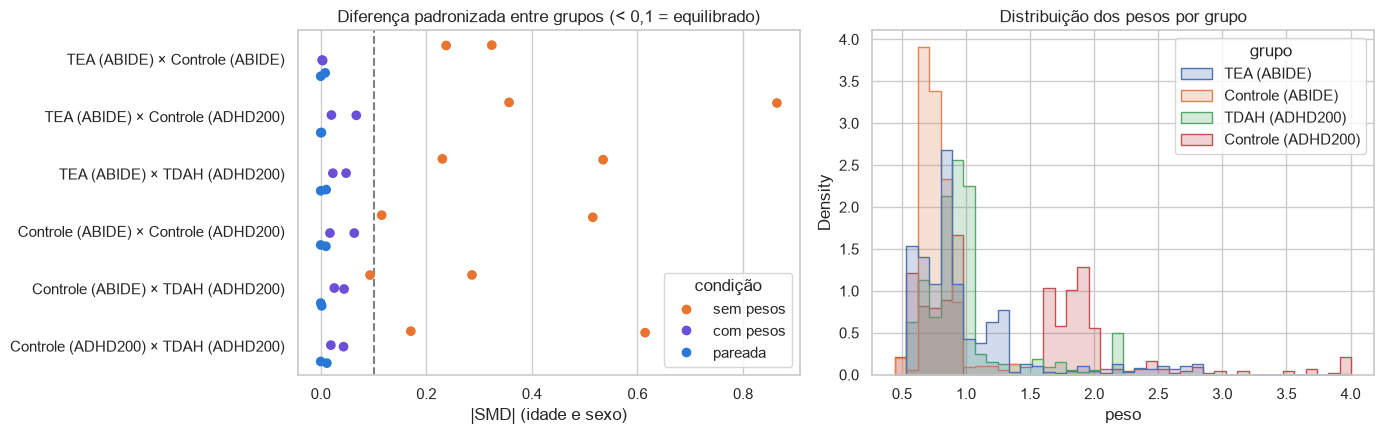

In [3]:
pares = [(a, b) for i, a in enumerate(GRUPOS) for b in GRUPOS[i + 1:]]
smd = []
for a, b in pares:
    for col, nome in [("age", "idade"), ("sexo_m", "sexo")]:
        smd.append({"par": f"{a} × {b}", "variável": nome,
                    "sem pesos": weighted_smd(c, col, a, b), "com pesos": weighted_smd(c, col, a, b, w),
                    "pareada": weighted_smd(p, col, a, b)})
smd = pd.DataFrame(smd)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
longo = smd.melt(id_vars=["par", "variável"], var_name="condição", value_name="SMD").assign(SMD=lambda x: x.SMD.abs())
sns.stripplot(data=longo, y="par", x="SMD", hue="condição", dodge=True, ax=ax[0], size=7,
              palette={"sem pesos": "#e8742f", "com pesos": "#6a4fd8", "pareada": "#2a78d6"})
ax[0].axvline(0.1, ls="--", c="gray"); ax[0].set_xlabel("|SMD| (idade e sexo)"); ax[0].set_ylabel("")
ax[0].set_title("Diferença padronizada entre grupos (< 0,1 = equilibrado)")
sns.histplot(x=w, hue=c.grupo, element="step", stat="density", common_norm=False, bins=40, ax=ax[1])
ax[1].set_xlabel("peso"); ax[1].set_title("Distribuição dos pesos por grupo")
fig.tight_layout(); fig.savefig(FIG / "07_pesos_equilibrio.png", dpi=150)
smd.round(2)

## 2. Teste de viés: com os pesos, os controles das duas bases ainda se distinguem?
Random Forest prevendo a base (ABIDE × ADHD-200) entre controles com as features do modelo, validação por instituição.
Acaso = 0,50.

In [4]:
def vies(df, peso=None, seeds=SEEDS):
    ctrl = (df.diagnosis == "Controle").to_numpy()
    Xc, yc = features(df[ctrl], "qi"), (df.dataset[ctrl] == "ABIDE").astype(int).to_numpy()
    wc = None if peso is None else np.asarray(peso)[ctrl]
    rf = make_pipeline(_imputer(RANDOM_STATE), RandomForestClassifier(300, min_samples_leaf=5, class_weight="balanced",
                                                                      random_state=RANDOM_STATE, n_jobs=-1))
    r, _ = repeated_group_cv(rf, Xc, yc, df.institution[ctrl], seeds=seeds, fit_weight=wc, eval_weight=wc,
                             metric_fn=partial(metrics_binary, nomes=("ADHD200", "ABIDE")))
    return r.acc_balanceada

v = pd.DataFrame({"Completa, sem pesos": vies(completa), "Completa, pesos sexo × idade": vies(completa, w),
                  "Pareada": vies(pareada)})
v.agg(["mean", "std"]).T.round(3)

,mean,std
"Completa, sem pesos",0.513,0.030
"Completa, pesos sexo × idade",0.461,0.034
Pareada,0.457,0.035


## 3. Desempenho nas quatro condições
Para cada condição e semente, as probabilidades fora da dobra são guardadas, e as métricas são calculadas
com ou sem pesos na avaliação.

In [5]:
def oof(model, X, y, groups, fit_weight=None, seeds=SEEDS):
    return [cross_val_predict(model, X, y, groups=groups, method="predict_proba",
                              cv=GroupKFold(5, shuffle=True, random_state=s), params=_fit_params(model, fit_weight))
            for s in seeds]

def tabela(probas, y, eval_weight=None):
    kw = {} if eval_weight is None else {"sample_weight": eval_weight}
    return pd.DataFrame([{"semente": s, **metrics(y, pr, **kw)} for s, pr in zip(SEEDS, probas)])

modelos = [n for n in make_models() if n != "LDA"]
Xp, yp, gp = features(pareada, "qi"), target(pareada), pareada.institution
Xc, yc, gc = features(completa, "qi"), target(completa), completa.institution
Xc_sem_idade = Xc.drop(columns="idade")

res, probas_pond = {}, {}
for nome in modelos:
    mk = lambda: make_models()[nome]
    pr_p = oof(mk(), Xp, yp, gp)
    pr_c = oof(mk(), Xc, yc, gc)
    pr_w = oof(mk(), Xc, yc, gc, fit_weight=w)
    pr_s = oof(mk(), Xc_sem_idade, yc, gc, fit_weight=w)
    res[(nome, "Pareada")] = tabela(pr_p, yp)
    res[(nome, "Completa, só classe (aval. sem pesos)")] = tabela(pr_c, yc)
    res[(nome, "Completa, só classe (aval. com pesos)")] = tabela(pr_c, yc, w)
    res[(nome, "Completa, sexo × idade")] = tabela(pr_w, yc, w)
    res[(nome, "Completa, sexo × idade, sem idade")] = tabela(pr_s, yc, w)
    probas_pond[nome] = pr_w[0]
    print(nome, "ok")

CONDS = list(dict.fromkeys(k[1] for k in res))
resumo = pd.DataFrame({k: r.acc_balanceada for k, r in res.items()}).agg(["mean", "std"]).T
resumo.index.names = ["modelo", "condição"]
resumo.unstack("condição")["mean"][CONDS].round(3)

Regressão logística ok


Árvore de decisão ok


Random Forest ok


XGBoost ok


condição,Pareada,"Completa, só classe (aval. sem pesos)","Completa, só classe (aval. com pesos)","Completa, sexo × idade","Completa, sexo × idade, sem idade"
modelo,,,,,
Random Forest,0.383,0.402,0.370,0.372,0.374
Regressão logística,0.378,0.448,0.382,0.390,0.404
XGBoost,0.374,0.410,0.371,0.374,0.380
Árvore de decisão,0.396,0.385,0.361,0.404,0.404


C:\Users\romer\AppData\Local\Temp\ipykernel_6560\2296300652.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([t.get_text().replace(", ", ",\n", 1) for t in ax.get_xticklabels()], fontsize=9)


condição,Pareada,"Completa, só classe (aval. sem pesos)","Completa, só classe (aval. com pesos)","Completa, sexo × idade","Completa, sexo × idade, sem idade"
modelo,,,,,
Random Forest,0.014,0.006,0.006,0.009,0.013
Regressão logística,0.012,0.006,0.007,0.013,0.007
XGBoost,0.018,0.006,0.004,0.007,0.009
Árvore de decisão,0.019,0.012,0.012,0.020,0.019


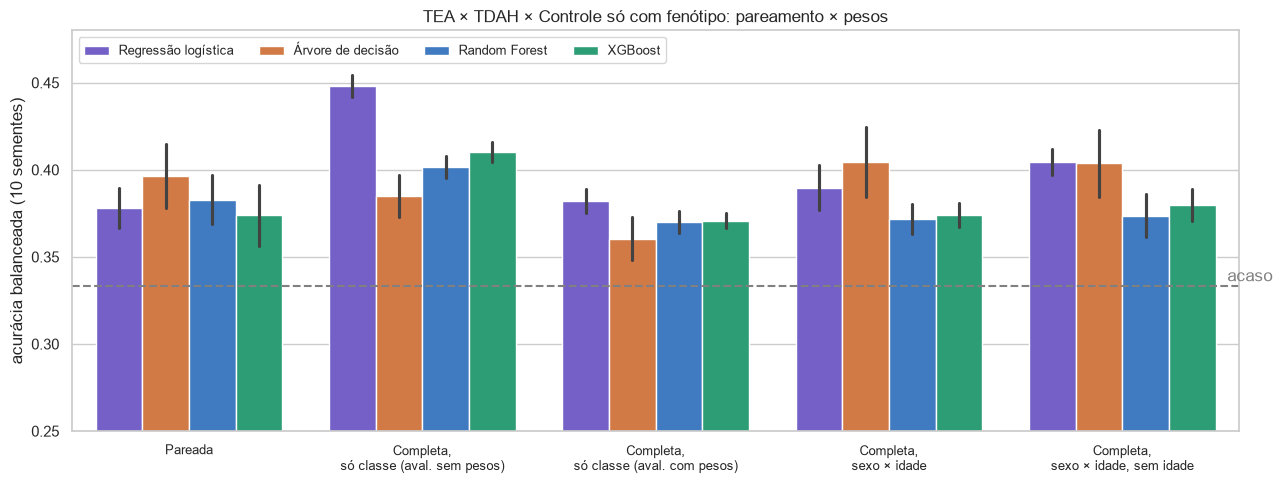

In [6]:
longo = pd.concat([r.assign(modelo=m, condição=cnd) for (m, cnd), r in res.items()])
cores = {"Regressão logística": "#6a4fd8", "Árvore de decisão": "#e8742f", "Random Forest": "#2a78d6", "XGBoost": "#1baf7a"}
fig, ax = plt.subplots(figsize=(13, 5))
sns.barplot(data=longo, x="condição", y="acc_balanceada", hue="modelo", palette=cores, errorbar="sd", ax=ax)
ax.axhline(1 / 3, ls="--", c="gray"); ax.text(4.45, 0.336, "acaso", color="gray")
ax.set_ylim(0.25, 0.48); ax.set_xlabel(""); ax.set_ylabel("acurácia balanceada (10 sementes)")
ax.set_xticklabels([t.get_text().replace(", ", ",\n", 1) for t in ax.get_xticklabels()], fontsize=9)
ax.set_title("TEA × TDAH × Controle só com fenótipo: pareamento × pesos")
ax.legend(fontsize=9, ncol=4, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "07_comparacao_coortes.png", dpi=150)
resumo.unstack("condição")["std"][CONDS].round(3)

### Quanto do resultado "só pesos de classe" era atalho?
Mesmo modelo, mesmas predições: avaliadas sem pesos e com pesos de sexo × idade. A queda é a parte do acerto que
vinha de sexo e idade.

In [7]:
atalho = pd.DataFrame({m: res[(m, "Completa, só classe (aval. sem pesos)")].acc_balanceada
                       - res[(m, "Completa, só classe (aval. com pesos)")].acc_balanceada for m in modelos})
atalho.agg(["mean", "std"]).T.round(3)

,mean,std
Regressão logística,0.066,0.004
Árvore de decisão,0.024,0.007
Random Forest,0.032,0.004
XGBoost,0.039,0.004


### Comitês × árvore com pesos de sexo × idade
Diferença pareada por semente (mesmas dobras) e Wilcoxon; com 10 repetições não independentes, o p-valor é indicativo.

In [8]:
cond = "Completa, sexo × idade"
arv = res[("Árvore de decisão", cond)]
linhas = []
for m in [x for x in modelos if x != "Árvore de decisão"]:
    for met in ["acc_balanceada", "confusao_TEA_TDAH"]:
        dif = res[(m, cond)][met] - arv[met]
        linhas.append({"comparação": f"{m} − Árvore", "métrica": met, "diferença_média": dif.mean(), "dp": dif.std(),
                       "p_wilcoxon": stats.wilcoxon(dif).pvalue})
pd.DataFrame(linhas).round(3)

,comparação,métrica,diferença_média,dp,p_wilcoxon
0,Regressão logística − Árvore,acc_balanceada,-0.015,0.029,0.131
1,Regressão logística − Árvore,confusao_TEA_TDAH,0.040,0.052,0.084
2,Random Forest − Árvore,acc_balanceada,-0.033,0.021,0.004
3,Random Forest − Árvore,confusao_TEA_TDAH,0.010,0.039,0.557
4,XGBoost − Árvore,acc_balanceada,-0.030,0.021,0.004
5,XGBoost − Árvore,confusao_TEA_TDAH,0.026,0.038,0.105


In [9]:
cond_tab = pd.concat({m: res[(m, cond)].drop(columns="semente").mean() for m in modelos}, axis=1).T
cond_tab.round(3)

,acc_balanceada,sens_Controle,sens_TDAH,sens_TEA,auc_macro_ovr,confusao_TEA_TDAH
Regressão logística,0.390,0.510,0.258,0.401,0.574,0.309
Árvore de decisão,0.404,0.581,0.225,0.407,0.568,0.268
Random Forest,0.372,0.550,0.127,0.438,0.554,0.278
XGBoost,0.374,0.568,0.153,0.401,0.551,0.294


## 4. Matriz de confusão ponderada (semente 0, com pesos de sexo × idade)

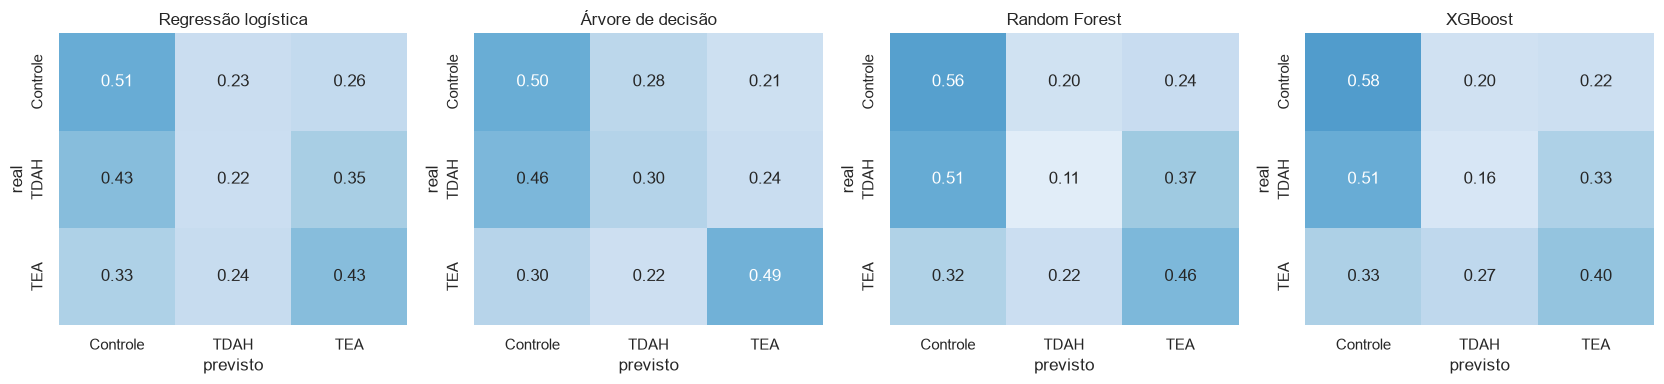

In [10]:
fig, ax = plt.subplots(1, len(modelos), figsize=(4.2 * len(modelos), 4))
for a, nome in zip(ax, modelos):
    pred = probas_pond[nome].argmax(axis=1)
    cm = pd.crosstab(pd.Series(yc, name="real"), pd.Series(pred, name="prev"), values=w, aggfunc="sum")
    cm = cm.reindex(index=range(3), columns=range(3), fill_value=0)
    sns.heatmap(cm.div(cm.sum(axis=1), axis=0), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=a,
                xticklabels=CLASSES, yticklabels=CLASSES)
    a.set_title(nome); a.set_xlabel("previsto"); a.set_ylabel("real")
fig.tight_layout(); fig.savefig(FIG / "07_confusao_ponderada.png", dpi=150)

## 5. E a idade? Importa para o neurodesenvolvimento?

Clinicamente, idade importa muito: o cérebro e a conectividade mudam durante a infância e a adolescência, a
hiperatividade do TDAH costuma diminuir com a idade, e a idade de diagnóstico varia entre TEA e TDAH. **O problema não
é a idade ser irrelevante; é a diferença de idade entre os grupos vir do recrutamento das bases**, e não do transtorno.

Três leituras abaixo:
1. Sem pesos, quanto a idade sozinha prevê o diagnóstico (só pela composição das amostras)?
2. Com pesos, a idade ainda ajuda? (comparação "com" × "sem a feature idade" da seção 3)
3. Coeficientes da regressão logística ponderada: o que sobra de sinal depois de equilibrar sexo e idade.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import SplineTransformer

so_idade = make_pipeline(SplineTransformer(n_knots=5), LogisticRegression(class_weight="balanced", max_iter=2000))
X_idade = completa[["age"]].to_numpy(float)
linhas = []
for rot, fw in [("sem pesos", None), ("com pesos", w)]:
    r, _ = repeated_group_cv(so_idade, X_idade, yc, gc, seeds=SEEDS, fit_weight=fw, eval_weight=fw)
    linhas.append({"avaliação": rot, "acc_bal só idade": r.acc_balanceada.mean(), "dp": r.acc_balanceada.std()})
print("Prevendo o diagnóstico SÓ com a idade (acaso 0,33):")
display(pd.DataFrame(linhas).round(3))

dif_idade = pd.DataFrame({m: res[(m, "Completa, sexo × idade")].acc_balanceada
                          - res[(m, "Completa, sexo × idade, sem idade")].acc_balanceada for m in modelos})
print("Ganho de incluir a feature idade, com pesos (com − sem):")
dif_idade.agg(["mean", "std"]).T.round(3)

Prevendo o diagnóstico SÓ com a idade (acaso 0,33):


,avaliação,acc_bal só idade,dp
0,sem pesos,0.361,0.013
1,com pesos,0.243,0.021


Ganho de incluir a feature idade, com pesos (com − sem):


,mean,std
Regressão logística,-0.015,0.013
Árvore de decisão,0.001,0.021
Random Forest,-0.002,0.010
XGBoost,-0.006,0.007


,Controle,TDAH,TEA
idade,0.02,-0.03,0.01
sexo_m,-0.04,0.03,0.01
qi_total,0.37,-0.14,-0.23
qi_verbal,0.01,0.05,-0.06
qi_execucao,-0.02,-0.05,0.08
discrep_viq_piq,0.04,0.10,-0.14


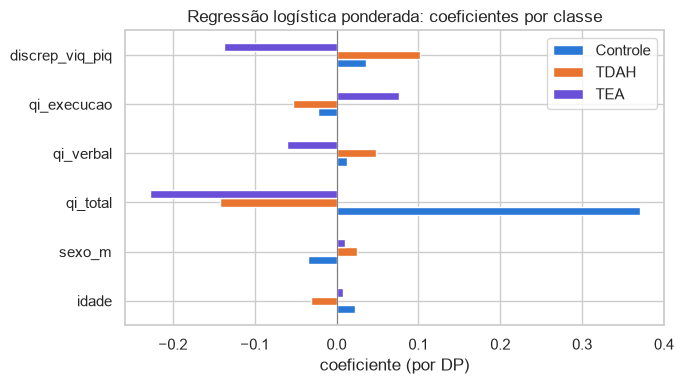

In [12]:
rl = make_models()["Regressão logística"]
rl.fit(Xc, yc, **_fit_params(rl, w))
coef = pd.DataFrame(rl[-1].coef_, index=CLASSES, columns=Xc.columns).T
ax = coef.plot.barh(figsize=(7, 4), color=["#2a78d6", "#e8742f", "#6a4fd8"]); ax.axvline(0, c="gray", lw=0.8)
ax.set_xlabel("coeficiente (por DP)"); ax.set_title("Regressão logística ponderada: coeficientes por classe")
plt.tight_layout(); plt.savefig(FIG / "07_coeficientes_ponderada.png", dpi=150)
coef.round(2)

## 6. Leitura dos resultados

**Os pesos funcionam como pareamento, sem descartar ninguém.** Com eles, todas as diferenças de idade e sexo entre
os quatro grupos ficam com |SMD| ≤ 0,07 (antes: até 0,86 em sexo). O tamanho efetivo é de ~1890 sujeitos,
contra 1136 do pareamento (+66%). O teste de viés entre controles cai de 0,51 (sem pesos) para 0,46,
igual ao da coorte pareada (0,46): as features comuns não denunciam a base.

**Só pesos de classe enganam.** Na coorte completa, sem pesos de sexo e idade, a regressão logística chega a 0,45 —
o melhor número de todo o fenótipo. Mas as mesmas predições, avaliadas numa população com sexo e idade equilibrados,
caem para 0,38: **0,07 do acerto era atalho** (RF 0,03, XGBoost 0,04, árvore 0,02). É o confundimento de recrutamento
aparecendo como "desempenho".

**Com pesos de sexo × idade, o resultado é o mesmo do pareamento:** árvore 0,40, logística 0,39, XGBoost 0,37,
RF 0,37 (pareada: 0,40 / 0,38 / 0,37 / 0,38). Dobrar a amostra efetiva não trouxe ganho; o limite é de sinal, não de
tamanho. Os comitês continuam abaixo da árvore (RF e XGBoost −0,03, p = 0,004). O TDAH segue a classe mais difícil
(sensibilidade 0,13–0,26) e ~30% dos casos TEA/TDAH são confundidos entre si.

**A idade não carrega sinal diagnóstico.** Sozinha, sem pesos, ela prevê o diagnóstico um pouco acima do acaso (0,36),
só pela composição das amostras; com pesos, nada (0,24). Retirar a feature idade não piora nenhum modelo
(logística até melhora, 0,39 → 0,40). Coerente com TEA, TDAH e TEAF serem transtornos do desenvolvimento inicial: a idade
muda a forma como aparecem, não se existem, e aqui ela só funcionava como marca do recrutamento. O pouco sinal que sobra
vem do QI total (mais alto nos controles), com discrepância VIQ − PIQ mais negativa no TEA.

**Decisão:** para fenótipo, os pesos de sexo × idade (`src/weighting.py`) substituem o pareamento como abordagem
principal, por usar todos os sujeitos com o mesmo controle de viés; a idade sai das features. O pareamento fica como
análise de sensibilidade. A conclusão do notebook 03 não muda: fenótipo comum às bases tem pouco sinal, e nenhum
comitê supera a árvore.